# UdaciHealth – Diabetes Risk Pre-Screening with a PyTorch MLP

**Client:** Regional hospital network  |  **Goal:** automated pre-screening that prioritizes diagnostic testing  |  **Data:** CDC Diabetes Health Indicators (BRFSS 2015)

**Problem.** The hospital network cannot run comprehensive diabetes tests on every patient. A pre-screening classifier should flag the patients most likely to be diabetic so the limited tests go where they matter most. The classifier must **catch most diabetic patients (high recall)** while keeping **false alarms at an acceptable level (reasonable precision)**.

**Dataset.** `data/diabetes_data.csv` is the *balanced 50/50* file from the CDC release (`diabetes_binary_5050split_health_indicators_BRFSS2015.csv`): 70,692 survey respondents (35,346 per class) and 21 health / lifestyle features. (The project brief quotes "~50,000" rows; the file supplied contains 70,692.) The original imbalanced file (253,680 rows, ~14 % diabetes) is also in `data/` and is used in the stand-out experiment in Section 6.6.2.

**Notebook map**

| Section | Content |
|---|---|
| 0 | Environment, seeds, device |
| 1 | Data loading and exploration (TODO 1–6) |
| 2 | Preprocessing pipeline (TODO 7–11) |
| 3 | Model architecture, forward pass, loss and optimizer (TODO 12–15) |
| 4 | Training loop, loss curves, diagnosis (TODO 16–17) |
| 5 | Evaluation: metrics, confusion matrix, ROC, interpretation (TODO 18–22) |
| 6 | Tuning and regularization experiments, comparison table, reflection (TODO 23–28) + stand-out experiments |
| 7 | Final model and conclusions |

> **A note on expectations.** The brief mentions "95–99 % accuracy". On this balanced data set the signal is limited (the survey has no lab values such as HbA1c or glucose), and the realistic ceiling for any model is roughly 75 % accuracy / 0.83 AUC. Chasing 95 %+ would require label leakage, so this notebook optimizes for the *clinically meaningful* metrics instead and states the real numbers.

## 0. Set Up the Environment

Import the libraries, fix the random seeds (reproducibility) and select the GPU if one is available, otherwise the CPU.

In [1]:
import os, random, copy, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

SEED = 42

def set_seed(seed=SEED):
    """Make Python, NumPy and PyTorch random number generators reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version : {torch.__version__}")
print(f"Using device    : {device}")

PyTorch version : 2.14.1+cu130
Using device    : cpu


## 1. Load and Explore the Dataset

We load the CDC *Diabetes Health Indicators* data (BRFSS 2015, balanced 50/50 subset) and study its structure before any modelling decision is taken.

In [2]:
# Load the balanced CDC Diabetes Health Indicators dataset
DATA_PATH = os.path.join("data", "diabetes_data.csv")
df = pd.read_csv(DATA_PATH)
TARGET = "Diabetes_binary"

### 1.1 Basic information

In [3]:
# TODO 1: Display basic information about the dataset
print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes.value_counts())
print()
df.info()
df.head()

Shape (rows, columns): (70692, 22)

Columns: ['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Data types:
float64    22
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActi

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


### 1.2 Missing values

In [4]:
# TODO 2: Check for missing values (and duplicates)
missing = df.isnull().sum()
print("Total missing values:", int(missing.sum()))
print(missing[missing > 0] if missing.sum() > 0 else "No column has missing values.")
print("\nExact duplicate rows:", int(df.duplicated().sum()),
      f"({df.duplicated().mean():.2%} of rows)")

Total missing values: 0
No column has missing values.

Exact duplicate rows: 1635 (2.31% of rows)


### 1.3 Target variable distribution (class balance)

                            count  percent
0 = No diabetes             35346     50.0
1 = Diabetes / prediabetes  35346     50.0


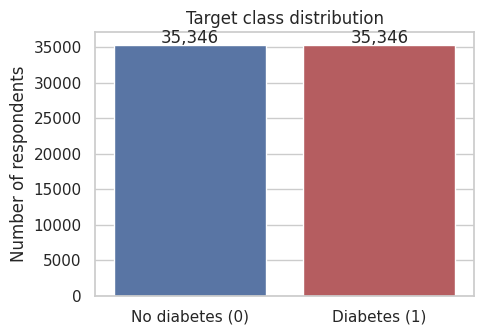

In [5]:
# TODO 3: Analyze the target variable distribution (class balance)
counts = df[TARGET].value_counts().sort_index()
percent = df[TARGET].value_counts(normalize=True).sort_index() * 100
target_summary = pd.DataFrame({"count": counts, "percent": percent.round(2)})
target_summary.index = ["0 = No diabetes", "1 = Diabetes / prediabetes"]
print(target_summary)

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=["No diabetes (0)", "Diabetes (1)"], y=counts.values, palette=["#4C72B0", "#C44E52"], ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 300, f"{v:,}", ha="center")
ax.set_ylabel("Number of respondents")
ax.set_title("Target class distribution")
plt.tight_layout(); plt.show()

### 1.4 Statistical properties of the features

Number of binary (0/1) features: 14


,count,mean,std,min,25%,50%,75%,max,skew
HighBP,70692.0,0.56,0.50,0.0,0.0,1.0,1.0,1.0,-0.26
HighChol,70692.0,0.53,0.50,0.0,0.0,1.0,1.0,1.0,-0.10
CholCheck,70692.0,0.98,0.16,0.0,1.0,1.0,1.0,1.0,-6.12
BMI,70692.0,29.86,7.11,12.0,25.0,29.0,33.0,98.0,1.72
Smoker,70692.0,0.48,0.50,0.0,0.0,0.0,1.0,1.0,0.10
Stroke,70692.0,0.06,0.24,0.0,0.0,0.0,0.0,1.0,3.63
HeartDiseaseorAttack,70692.0,0.15,0.35,0.0,0.0,0.0,0.0,1.0,1.98
PhysActivity,70692.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0,-0.89
Fruits,70692.0,0.61,0.49,0.0,0.0,1.0,1.0,1.0,-0.46
Veggies,70692.0,0.79,0.41,0.0,1.0,1.0,1.0,1.0,-1.41


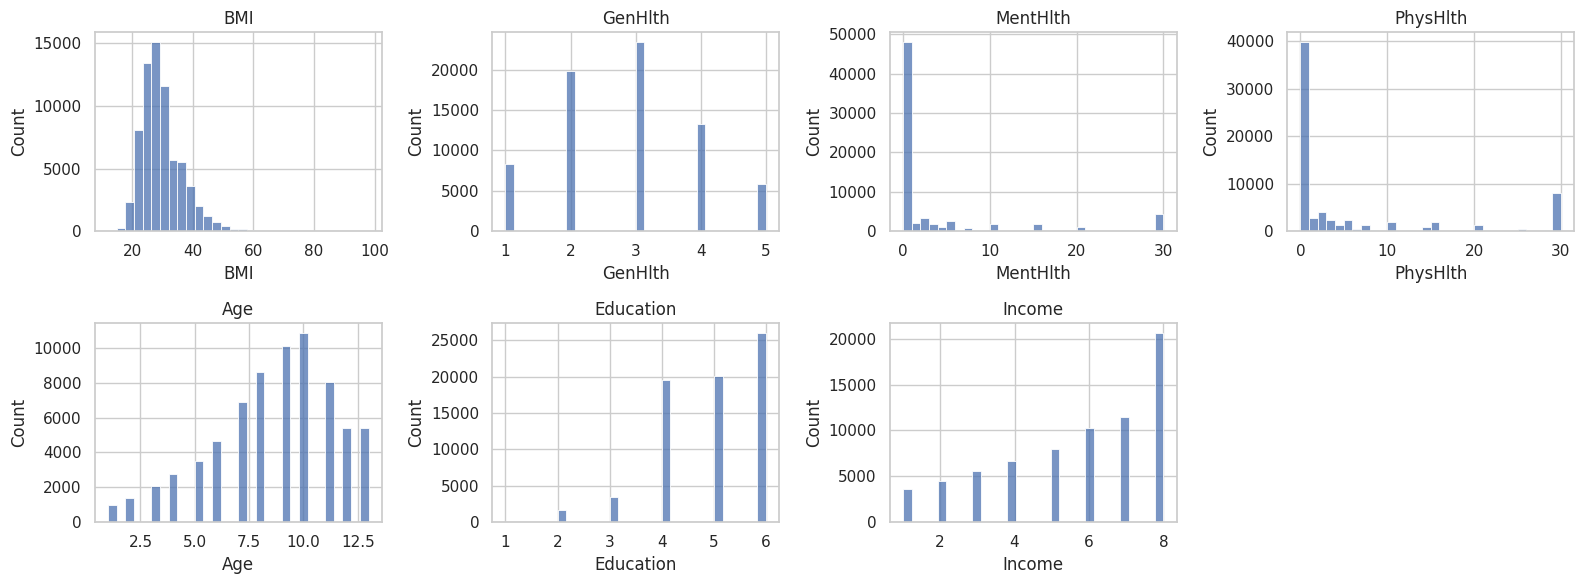

In [6]:
# TODO 4: Examine statistical properties of the features
stats = df.drop(columns=[TARGET]).describe().T
stats["skew"] = df.drop(columns=[TARGET]).skew()
print("Number of binary (0/1) features:", sum(df[c].nunique() == 2 for c in df.columns if c != TARGET))
display(stats.round(2))

# Visualize the scale / shape of the non-binary features
non_binary = [c for c in df.columns if c != TARGET and df[c].nunique() > 2]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), non_binary):
    sns.histplot(df[col], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col)
for ax in axes.ravel()[len(non_binary):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### 1.5 Correlation analysis

,correlation with Diabetes_binary
GenHlth,0.408
HighBP,0.382
BMI,0.293
HighChol,0.289
Age,0.279
DiffWalk,0.273
PhysHlth,0.213
HeartDiseaseorAttack,0.212
Stroke,0.125
CholCheck,0.115


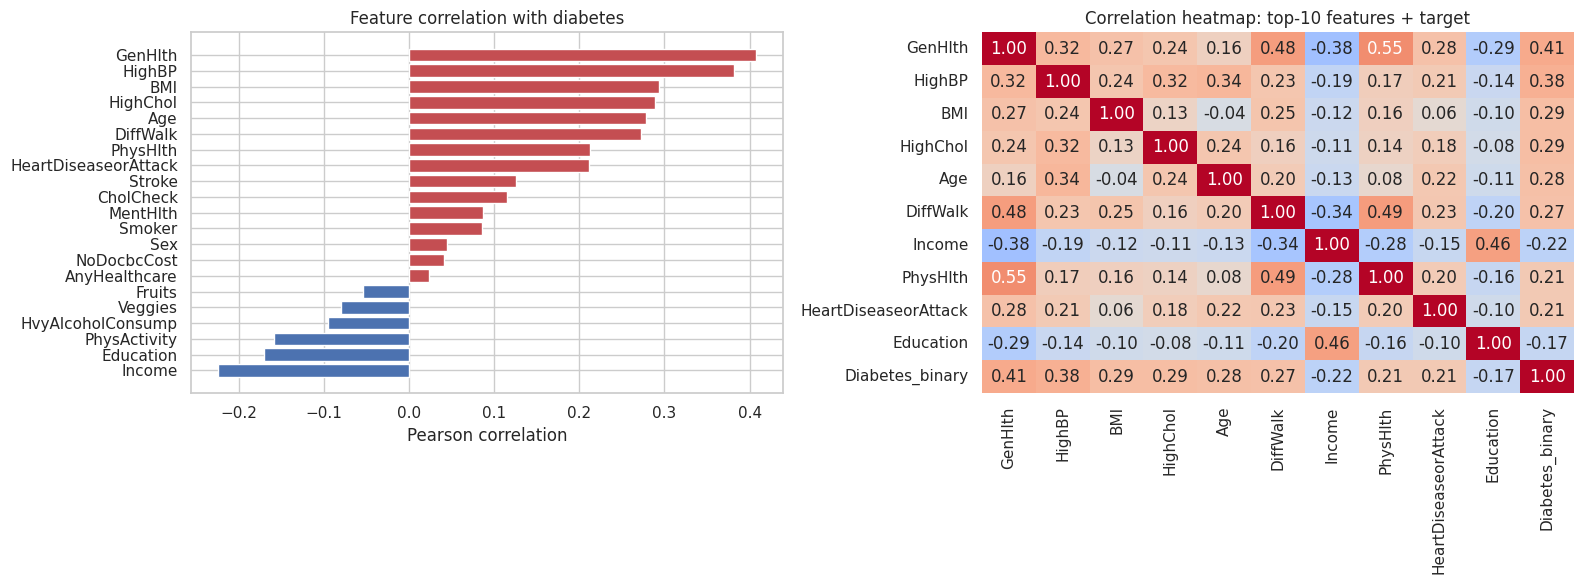

Most correlated feature pairs (|r|):
GenHlth    PhysHlth    0.55
PhysHlth   DiffWalk    0.49
GenHlth    DiffWalk    0.48
Education  Income      0.46
GenHlth    Income      0.38
dtype: float64


In [7]:
# TODO 5: Correlation analysis between features and the target
corr_with_target = df.corr()[TARGET].drop(TARGET).sort_values(ascending=False)
display(corr_with_target.round(3).to_frame("correlation with Diabetes_binary"))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in corr_with_target.values]
axes[0].barh(corr_with_target.index[::-1], corr_with_target.values[::-1], color=colors[::-1])
axes[0].set_title("Feature correlation with diabetes"); axes[0].set_xlabel("Pearson correlation")

top = corr_with_target.abs().sort_values(ascending=False).head(10).index.tolist()
sns.heatmap(df[top + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1], cbar=False)
axes[1].set_title("Correlation heatmap: top-10 features + target")
plt.tight_layout(); plt.show()

# Strongest correlations *between features* (redundancy check)
feat_corr = df.drop(columns=[TARGET]).corr().abs()
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False).head(5))
print("Most correlated feature pairs (|r|):")
print(pairs.round(2))

### 1.6 Observations about the dataset (TODO 6)

**What the exploration tells us**

* **Size and quality.** 70,692 rows × 22 columns (21 features + target), all numeric, **no missing values**, so no imputation is needed. 1,635 rows (2.3 %) are exact duplicates; for survey data identical answers from different people are plausible (many columns are binary), so they were kept – the cost is that a few identical rows can land in different splits, which slightly flatters the metrics.
* **Class balance.** Exactly 50 % / 50 % (35,346 per class), so accuracy is meaningful here, but this is *not* the real-world prevalence (~14 %). Precision on real patients would be lower than reported here (see Section 6.6.2).
* **Feature types.** 14 of the 21 features are binary flags; the other seven are numeric or ordinal (`BMI`, `GenHlth` 1–5, `MentHlth` / `PhysHlth` 0–30, `Age` 1–13, `Education` 1–6, `Income` 1–8). The scales differ by more than an order of magnitude, so **standardization is required** for gradient-based training.
* **Skew and outliers.** `BMI` (skew 1.7, max 98), `MentHlth` (skew 2.4) and `PhysHlth` (skew 1.7) are right-skewed with long tails. We keep them as they are (an MLP with scaling copes with this), but it is a potential refinement.
* **Strongest relationships.** Correlation with diabetes: `GenHlth` (+0.41), `HighBP` (+0.38), `BMI` (+0.29), `HighChol` (+0.29), `Age` (+0.28), `DiffWalk` (+0.27); protective direction: `Income` (−0.22), `Education` (−0.17), `PhysActivity` (−0.16). Group means agree: respondents with diabetes have a mean BMI of ~31.9 vs ~27.8, and 75 % have high blood pressure vs 37 %.
* **Weak features.** `AnyHealthcare`, `NoDocbcCost`, `Sex`, `Fruits`, `Smoker` all have |r| < 0.09.
* **Redundancy.** The largest feature–feature correlations are moderate (`GenHlth`–`PhysHlth` 0.55, `DiffWalk`–`PhysHlth` 0.49, `GenHlth`–`DiffWalk` 0.48) – nothing severe enough to drop features.
* **Implications for modelling.** (1) No single feature has |r| above 0.41, so the signal is spread over many weak, partly non-linear relationships – a good fit for an MLP but also a hint that the achievable performance is limited; (2) stratified splitting keeps the 50/50 balance in every split; (3) because missing a diabetic patient is costlier than an extra test, **recall** will be the metric we watch most closely.

## 2. Preprocess the Dataset

Pipeline: separate X / y → stratified 60/20/20 split → scale (fit on train only) → tensors → DataLoaders.

### 2.1 Separate features and target

In [8]:
# TODO 7: Separate features (X) from the target (y)
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)
print("X shape:", X.shape, "| y shape:", y.shape)
print("Feature names:", list(X.columns))

X shape: (70692, 21) | y shape: (70692,)
Feature names: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


### 2.2 Stratified train / validation / test split

In [9]:
# TODO 8: Create stratified 60 / 20 / 20 train / validation / test splits
# Step 1: hold out 20% for the final test set. Step 2: split the remaining 80% into 60% train / 20% validation
# (0.25 of 80% = 20% of the total). stratify= keeps the class proportions identical in every split.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=SEED)

for name, ys in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<10}: {len(ys):>6,} rows ({len(ys)/len(y):.0%}) | diabetes rate = {ys.mean():.3f}")

Train     : 42,414 rows (60%) | diabetes rate = 0.500
Validation: 14,139 rows (20%) | diabetes rate = 0.500
Test      : 14,139 rows (20%) | diabetes rate = 0.500


### 2.3 Normalization – *the Golden Rule*

The scaler learns the mean and standard deviation from the **training split only**; validation and test data are merely transformed with those statistics. Fitting on all data would leak information about the unseen splits into training.

In [10]:
# TODO 9: Normalize features (the "Golden Rule": fit the scaler on TRAINING data only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from train only
X_val_scaled = scaler.transform(X_val)           # re-use train statistics (no leakage)
X_test_scaled = scaler.transform(X_test)

print("Train mean (first 5 features):", X_train_scaled.mean(axis=0)[:5].round(3))
print("Train std  (first 5 features):", X_train_scaled.std(axis=0)[:5].round(3))
print("Val   mean (first 5 features):", X_val_scaled.mean(axis=0)[:5].round(3), "<- close to, but not exactly, 0")

Train mean (first 5 features): [ 0.  0. -0. -0.  0.]
Train std  (first 5 features): [1. 1. 1. 1. 1.]
Val   mean (first 5 features): [-0.008 -0.004 -0.01  -0.003 -0.01 ] <- close to, but not exactly, 0


### 2.4 Convert to PyTorch tensors

In [11]:
# TODO 10: Convert NumPy arrays to PyTorch tensors
# Features -> float32. Targets -> float32 with shape (N, 1) because BCEWithLogitsLoss expects float targets
# with the same shape as the model output.
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t   = torch.tensor(X_val_scaled,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test_scaled,  dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
y_val_t   = torch.tensor(y_val.values,   dtype=torch.float32).unsqueeze(1)
y_test_t  = torch.tensor(y_test.values,  dtype=torch.float32).unsqueeze(1)

print("X_train:", X_train_t.shape, X_train_t.dtype, "| y_train:", y_train_t.shape, y_train_t.dtype)
print("X_val  :", X_val_t.shape,   "| y_val  :", y_val_t.shape)
print("X_test :", X_test_t.shape,  "| y_test :", y_test_t.shape)

X_train: torch.Size([42414, 21]) torch.float32 | y_train: torch.Size([42414, 1]) torch.float32
X_val  : torch.Size([14139, 21]) | y_val  : torch.Size([14139, 1])
X_test : torch.Size([14139, 21]) | y_test : torch.Size([14139, 1])


### 2.5 DataLoaders

In [12]:
# TODO 11: Create DataLoaders
BATCH_SIZE = 256
train_generator = torch.Generator().manual_seed(SEED)   # reproducible shuffling

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE,
                          shuffle=True, generator=train_generator)          # shuffle: training only
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t),   batch_size=1024, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=1024, shuffle=False)

print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Train batches: 166 | Val batches: 14 | Test batches: 14


## 3. Design the Model Architecture

A multi-layer perceptron with **two hidden layers (128 → 64)**, ReLU activations and a single output logit. For binary classification we output *one* raw score (logit) and let `BCEWithLogitsLoss` apply the sigmoid internally – numerically more stable than a separate `Sigmoid` + `BCELoss`. At inference time `torch.sigmoid(logit)` gives the probability of diabetes.

### 3.1 Define the network

In [13]:
# TODO 12: Define the neural network class (MLP for binary classification)
class DiabetesMLP(nn.Module):
    """Multi-layer perceptron: input -> [Linear -> ReLU (-> Dropout)] x N hidden layers -> 1 logit."""

    def __init__(self, input_dim, hidden_dims=(128, 64), dropout=0.0):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:                       # at least two hidden layers are passed in
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())                # non-linear activation for every hidden layer
            if dropout > 0:
                layers.append(nn.Dropout(dropout))  # regularization (used in the tuning section)
            prev = h
        layers.append(nn.Linear(prev, 1))           # output layer: ONE raw logit for binary classification
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)                      # raw logits; sigmoid is applied inside the loss / at inference

    @torch.no_grad()
    def predict_proba(self, x):
        self.eval()
        return torch.sigmoid(self.forward(x))

INPUT_DIM = X_train_t.shape[1]

### 3.2 Instantiate the model

In [14]:
# TODO 13: Create the model instance and move it to the device
set_seed(SEED)
model = DiabetesMLP(input_dim=INPUT_DIM, hidden_dims=(128, 64), dropout=0.0).to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTrainable parameters: {n_params:,}")

DiabetesMLP(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

Trainable parameters: 11,137


### 3.3 Verify forward propagation

In [15]:
# TODO 14: Test the forward pass with one sample batch
sample_X, sample_y = next(iter(train_loader))
model.eval()
with torch.no_grad():
    sample_out = model(sample_X.to(device))

print("Input batch shape :", tuple(sample_X.shape))
print("Output shape      :", tuple(sample_out.shape), "(expected (batch_size, 1))")
print("First 5 logits    :", sample_out[:5].squeeze().cpu().numpy().round(3))
print("As probabilities  :", torch.sigmoid(sample_out[:5]).squeeze().cpu().numpy().round(3))
assert sample_out.shape == (sample_X.shape[0], 1), "Unexpected output shape!"
print("Forward pass OK")

Input batch shape : (256, 21)
Output shape      : (256, 1) (expected (batch_size, 1))
First 5 logits    : [-0.156 -0.318 -0.157 -0.322 -0.207]
As probabilities  : [0.461 0.421 0.461 0.42  0.448]
Forward pass OK


### 3.4 Loss function and optimizer

In [16]:
# TODO 15: Define the loss function and optimizer
# BCEWithLogitsLoss = sigmoid + binary cross-entropy in one numerically stable op (right for binary labels).
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)   # Adam with the common default learning rate
print(criterion)
print(optimizer)

BCEWithLogitsLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 4. Train the Model

### 4.1 Training loop

In [17]:
# TODO 16: Complete training loop
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=30,
                scheduler=None, early_stopping_patience=None, verbose=True):
    """Train `model` and return a history dict with per-epoch train/validation loss.

    Optional extras (used only in the tuning section): a learning-rate `scheduler` and
    early stopping (restores the weights of the best validation epoch).
    """
    history = {"train_loss": [], "val_loss": [], "lr": []}
    best_val, best_state, best_epoch, bad_epochs = float("inf"), None, 0, 0

    for epoch in range(1, epochs + 1):
        # ---------------- training phase ----------------
        model.train()
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()              # (5) zero the gradients from the previous step
            logits = model(xb)                 # (1) forward propagation
            loss = criterion(logits, yb)       # (2) loss calculation
            loss.backward()                    # (3) backpropagation
            optimizer.step()                   # (4) parameter update
            running += loss.item() * xb.size(0)
        train_loss = running / len(train_loader.dataset)

        # ---------------- validation phase (no gradient tracking) ----------------
        model.eval()
        running = 0.0
        with torch.no_grad():                  # (6) validation loss without building the autograd graph
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                running += criterion(model(xb), yb).item() * xb.size(0)
        val_loss = running / len(val_loader.dataset)

        # ---------------- bookkeeping ----------------
        history["train_loss"].append(train_loss)   # (7) epoch-level loss tracking
        history["val_loss"].append(val_loss)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        if val_loss < best_val - 1e-5:
            best_val, best_epoch, bad_epochs = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1

        if verbose and (epoch == 1 or epoch % 5 == 0 or epoch == epochs):
            print(f"Epoch {epoch:>3}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f}")

        if early_stopping_patience is not None and bad_epochs >= early_stopping_patience:
            if verbose:
                print(f"Early stopping at epoch {epoch} (best epoch = {best_epoch})")
            break

    history["best_epoch"], history["best_val_loss"] = best_epoch, best_val
    if early_stopping_patience is not None and best_state is not None:
        model.load_state_dict(best_state)      # restore the best weights
    return history

### 4.2 Train the baseline

In [18]:
# Train the baseline model (no regularization, fixed learning rate, 30 epochs)
EPOCHS = 30
baseline_history = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=EPOCHS)

Epoch   1/30 | train loss 0.5298 | val loss 0.5085


Epoch   5/30 | train loss 0.4990 | val loss 0.5036


Epoch  10/30 | train loss 0.4937 | val loss 0.5046


Epoch  15/30 | train loss 0.4891 | val loss 0.5049


Epoch  20/30 | train loss 0.4841 | val loss 0.5076


Epoch  25/30 | train loss 0.4793 | val loss 0.5104


Epoch  30/30 | train loss 0.4753 | val loss 0.5153


### 4.3 Loss curves

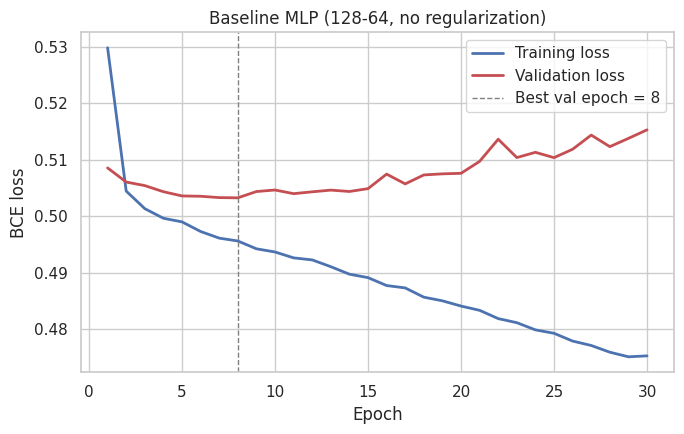

Lowest validation loss 0.5032 at epoch 8
Final epoch: train loss 0.4753 | val loss 0.5153
Generalization gap (val - train) at the final epoch: 0.0400


In [19]:
# Plot the training and validation loss curves
def plot_loss_curves(history, title="Training vs validation loss", ax=None):
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4.5))
    epochs = range(1, len(history["train_loss"]) + 1)
    ax.plot(epochs, history["train_loss"], label="Training loss", color="#4C72B0", lw=2)
    ax.plot(epochs, history["val_loss"], label="Validation loss", color="#C44E52", lw=2)
    ax.axvline(history["best_epoch"], color="gray", ls="--", lw=1, label=f"Best val epoch = {history['best_epoch']}")
    ax.set_xlabel("Epoch"); ax.set_ylabel("BCE loss"); ax.set_title(title); ax.legend()
    if show:
        plt.tight_layout(); plt.show()

plot_loss_curves(baseline_history, "Baseline MLP (128-64, no regularization)")
print(f"Lowest validation loss {baseline_history['best_val_loss']:.4f} at epoch {baseline_history['best_epoch']}")
print(f"Final epoch: train loss {baseline_history['train_loss'][-1]:.4f} | val loss {baseline_history['val_loss'][-1]:.4f}")
print(f"Generalization gap (val - train) at the final epoch: {baseline_history['val_loss'][-1] - baseline_history['train_loss'][-1]:.4f}")

### 4.4 Diagnosis of the loss curves (TODO 17)

**Pattern observed: mild overfitting that starts after roughly epoch 8–10.**

* **Training loss** decreases steadily for all 30 epochs (0.530 → 0.475). The network keeps fitting the training data better.
* **Validation loss** drops quickly at first (0.509 at epoch 1), reaches its minimum of **0.5032 at epoch 8**, and then *rises* again to 0.515 at epoch 30.
* The **generalization gap** (validation − training loss) therefore widens to about 0.040 by the last epoch.

**What this implies.** Up to ~epoch 8 the model learns patterns that generalize. After that, it starts to memorize noise in the training set: the training loss keeps improving while the unseen-data loss gets worse. The model is *not underfitting* (training loss is still falling and the validation loss is lower than the 0.693 of a random guess) – it has enough capacity, and what it lacks is regularization or an earlier stop. The overfitting is mild because the validation loss only increases by ~0.012 above its minimum, which is why the experiments in Section 6 test dropout, weight decay, early stopping, and smaller learning rates and networks.

## 5. Evaluate the Model

Accuracy alone is not enough for a screening tool, so we report precision, recall, F1 and AUC, with recall (sensitivity) as the clinically most important number.

### 5.1 Evaluation function (TODO 18)

In [20]:
# TODO 18: Implement the evaluation function
@torch.no_grad()
def evaluate_model(model, data_loader, threshold=0.5, verbose=True, name="Model"):
    """Return classification metrics (and raw predictions) for `model` on `data_loader`."""
    model.eval()
    probs, labels = [], []
    for xb, yb in data_loader:
        probs.append(torch.sigmoid(model(xb.to(device))).cpu().numpy().ravel())
        labels.append(yb.numpy().ravel())
    y_prob, y_true = np.concatenate(probs), np.concatenate(labels).astype(int)
    y_pred = (y_prob >= threshold).astype(int)

    metrics = {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, y_prob),
        "pr_auc":    average_precision_score(y_true, y_prob),
    }
    if verbose:
        print(f"{name} @ threshold {threshold:.2f}")
        for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
            print(f"  {k:<10}: {metrics[k]:.4f}")
    metrics.update({"y_true": y_true, "y_prob": y_prob, "y_pred": y_pred})
    return metrics

### 5.2 Evaluation on the test set (TODO 19)

In [21]:
# TODO 19: Run the evaluation on the TEST set
test_metrics = evaluate_model(model, test_loader, name="Baseline MLP - test set")
print()
print(classification_report(test_metrics["y_true"], test_metrics["y_pred"],
                            target_names=["No diabetes", "Diabetes"], digits=3))

Baseline MLP - test set @ threshold 0.50
  accuracy  : 0.7457
  precision : 0.7225
  recall    : 0.7977
  f1        : 0.7582
  roc_auc   : 0.8238

              precision    recall  f1-score   support

 No diabetes      0.774     0.694     0.732      7070
    Diabetes      0.722     0.798     0.758      7069

    accuracy                          0.746     14139
   macro avg      0.748     0.746     0.745     14139
weighted avg      0.748     0.746     0.745     14139



### 5.3 Confusion matrix (TODO 20)

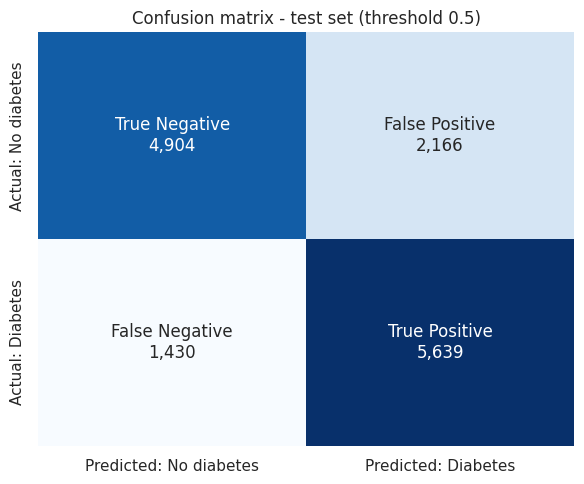

Missed diabetic patients (false negatives): 1,430 of 7,069 -> 20.2% of true cases
Unnecessary follow-ups   (false positives): 2,166 of 7,070 -> 30.6% of healthy patients


In [22]:
# TODO 20: Confusion matrix with clinical labels
cm = confusion_matrix(test_metrics["y_true"], test_metrics["y_pred"])
tn, fp, fn, tp = cm.ravel()
labels = np.array([[f"True Negative\n{tn:,}", f"False Positive\n{fp:,}"],
                   [f"False Negative\n{fn:,}", f"True Positive\n{tp:,}"]])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted: No diabetes", "Predicted: Diabetes"],
            yticklabels=["Actual: No diabetes", "Actual: Diabetes"])
ax.set_title("Confusion matrix - test set (threshold 0.5)")
plt.tight_layout(); plt.show()

print(f"Missed diabetic patients (false negatives): {fn:,} of {fn + tp:,} -> {fn/(fn+tp):.1%} of true cases")
print(f"Unnecessary follow-ups   (false positives): {fp:,} of {fp + tn:,} -> {fp/(fp+tn):.1%} of healthy patients")

### 5.4 ROC curve and AUC (TODO 21)

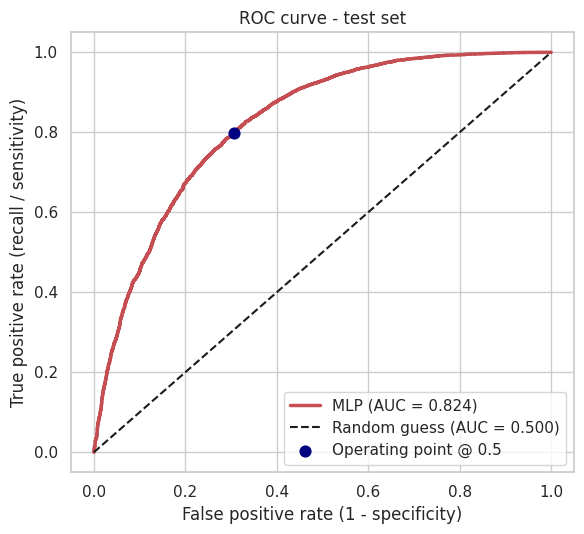

AUC = 0.8238


In [23]:
# TODO 21: ROC curve and AUC
fpr, tpr, roc_thresholds = roc_curve(test_metrics["y_true"], test_metrics["y_prob"])
auc_score = test_metrics["roc_auc"]

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot(fpr, tpr, color="#C44E52", lw=2.5, label=f"MLP (AUC = {auc_score:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random guess (AUC = 0.500)")
ax.scatter([fp / (fp + tn)], [tp / (tp + fn)], color="navy", zorder=5, s=60, label="Operating point @ 0.5")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (recall / sensitivity)")
ax.set_title("ROC curve - test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"AUC = {auc_score:.4f}")

### 5.5 Effect of the decision threshold

In [24]:
# Supporting analysis for TODO 22: how do the metrics change with the decision threshold?
# Thresholds are examined on the VALIDATION set so the test set stays untouched for model selection.
val_metrics = evaluate_model(model, val_loader, verbose=False)
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (val_metrics["y_prob"] >= t).astype(int)
    rows.append({"threshold": t,
                 "recall": recall_score(val_metrics["y_true"], pred),
                 "precision": precision_score(val_metrics["y_true"], pred),
                 "f1": f1_score(val_metrics["y_true"], pred),
                 "false positives": int(((pred == 1) & (val_metrics["y_true"] == 0)).sum()),
                 "false negatives": int(((pred == 0) & (val_metrics["y_true"] == 1)).sum())})
threshold_df = pd.DataFrame(rows).set_index("threshold")
display(threshold_df.round(3))

,recall,precision,f1,false positives,false negatives
threshold,,,,,
0.2,0.954,0.633,0.761,3913,328
0.3,0.918,0.664,0.770,3288,583
0.4,0.866,0.693,0.770,2718,945
0.5,0.803,0.725,0.762,2147,1396
0.6,0.707,0.758,0.732,1592,2070
0.7,0.570,0.792,0.663,1059,3037


### 5.6 Interpretation for diabetes screening (TODO 22)

**Baseline test-set results (threshold 0.5):** accuracy 0.746, precision 0.723, recall 0.798, F1 0.758, ROC-AUC 0.824. Confusion matrix: 1,430 of 7,069 diabetic patients are missed (20.2 %), and 2,166 of 7,070 healthy patients are flagged (30.6 %).

**1. Most important metric – recall (sensitivity), supported by precision.** In pre-screening, a **false negative** is a diabetic patient who is told "low risk": diagnosis is delayed, complications such as neuropathy, kidney and eye damage develop unnoticed, and treatment later costs far more. A **false positive** only triggers a confirmatory test (e.g., HbA1c or fasting glucose), which is cheap and harmless by comparison. So recall is the primary metric. It cannot be maximized alone, though: flagging everyone gives 100 % recall and defeats the purpose of prioritizing scarce tests. Precision (0.72) tells the hospital what share of its follow-up tests will find a real case, and the F1-score and AUC summarize the trade-off. Accuracy is the least informative number because the two error types have very different costs.

**2. Recommendation on deploying the baseline.** I would **not deploy this baseline as it is**. It is clearly better than chance (AUC 0.82), but one in five diabetic patients would still be missed, and its validation loss shows it overfits after epoch 8. It is a reasonable *starting point* for a triage tool, **not** a diagnostic one: positive results must always be confirmed by a lab test, and negatives must not be read as a clean bill of health. Before any real use the model should also be improved (Section 6), re-validated on recent local patient data (this survey is from 2015 and self-reported), checked for performance differences across age, sex and income groups, and calibrated for the true ~14 % prevalence, which lowers precision in practice.

**3. The 0.5 threshold versus alternatives.** 0.5 is a default, not a clinical decision. The threshold table above (validation set) shows the trade-off: at 0.4, recall rises from 0.80 to 0.87 and precision falls from 0.73 to 0.69; at 0.3, recall is 0.92 with precision 0.66; at 0.2, 95 % of diabetics are caught but 3,913 healthy patients are flagged. Raising the threshold to 0.6–0.7 reduces false alarms but misses 29–43 % of diabetics, which is unacceptable for screening. F1 is almost flat between 0.3 and 0.5, so lowering the threshold to about **0.35–0.4** buys a lot of recall for a small loss of precision. The final operating point should be set by the hospital from the real cost of a missed case vs. an extra test and the capacity of its testing lab, and must be chosen on validation data, never on the test set.

## 6. Improve and Tune the Model

We now run **controlled experiments**: each run changes one thing relative to the baseline (128-64, no dropout, Adam lr = 1e-3, batch 256, 30 epochs), with the same seed, split and data. Choices are made on **validation loss**; the test set is only used to *report* the metrics.

### 6.1 Experiment framework and baseline

In [25]:
# 6.1 Experiment framework -------------------------------------------------------------
# Every experiment re-seeds, rebuilds the model and the DataLoaders, so the ONLY thing that differs between
# two runs is the setting being studied (controlled experiments). Results are stored in `results`.
results = []

def make_data(X_df, y_series, seed=SEED):
    """Stratified 60/20/20 split + scaling fitted on train only -> dict of tensors (used for the bonus experiments)."""
    X_tv, X_te, y_tv, y_te = train_test_split(X_df, y_series, test_size=0.20, stratify=y_series, random_state=seed)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=0.25, stratify=y_tv, random_state=seed)
    sc = StandardScaler().fit(X_tr)
    f = lambda a: torch.tensor(sc.transform(a), dtype=torch.float32)
    g = lambda s: torch.tensor(s.values, dtype=torch.float32).unsqueeze(1)
    return dict(X_train=f(X_tr), X_val=f(X_va), X_test=f(X_te), y_train=g(y_tr), y_val=g(y_va), y_test=g(y_te))

DATA = dict(X_train=X_train_t, X_val=X_val_t, X_test=X_test_t, y_train=y_train_t, y_val=y_val_t, y_test=y_test_t)

def make_loaders(data, batch_size, seed):
    gen = torch.Generator().manual_seed(seed)
    tr = DataLoader(TensorDataset(data["X_train"], data["y_train"]), batch_size=batch_size, shuffle=True, generator=gen)
    va = DataLoader(TensorDataset(data["X_val"], data["y_val"]), batch_size=2048, shuffle=False)
    te = DataLoader(TensorDataset(data["X_test"], data["y_test"]), batch_size=2048, shuffle=False)
    return tr, va, te

def run_experiment(name, description, hidden_dims=(128, 64), dropout=0.0, lr=1e-3, weight_decay=0.0,
                   batch_size=256, epochs=30, patience=None, use_scheduler=False, pos_weight=None,
                   seed=SEED, data=None, store=True):
    """Train one configuration and record validation + test metrics (decision threshold 0.5)."""
    data = DATA if data is None else data
    set_seed(seed)
    tr, va, te = make_loaders(data, batch_size, seed)
    m = DiabetesMLP(data["X_train"].shape[1], hidden_dims, dropout).to(device)
    crit = nn.BCEWithLogitsLoss(pos_weight=None if pos_weight is None else torch.tensor([pos_weight], device=device))
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=weight_decay)   # Adam's weight_decay = L2 penalty
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2) if use_scheduler else None
    hist = train_model(m, tr, va, crit, opt, epochs=epochs, scheduler=sched,
                       early_stopping_patience=patience, verbose=False)
    vm = evaluate_model(m, va, verbose=False)
    tm = evaluate_model(m, te, verbose=False)
    rec = {"Experiment": name, "Change": description, "Epochs run": len(hist["train_loss"]),
           "Best epoch": hist["best_epoch"], "Best val loss": hist["best_val_loss"],
           "Final train loss": hist["train_loss"][-1], "Final val loss": hist["val_loss"][-1],
           "Val AUC": vm["roc_auc"],
           "Accuracy": tm["accuracy"], "Precision": tm["precision"], "Recall": tm["recall"],
           "F1": tm["f1"], "AUC": tm["roc_auc"],
           "_history": hist, "_model": m, "_cfg": dict(hidden_dims=hidden_dims, dropout=dropout, lr=lr,
                                                      weight_decay=weight_decay, batch_size=batch_size,
                                                      epochs=epochs, patience=patience, use_scheduler=use_scheduler)}
    if store:
        results.append(rec)
    return rec

def show(group, cols=("Experiment", "Change", "Best epoch", "Best val loss", "Final val loss", "Accuracy", "Precision", "Recall", "F1", "AUC")):
    out = pd.DataFrame([{k: r[k] for k in cols} for r in group]).set_index("Experiment")
    display(out.round(4))

def plot_group(group, title):
    n = len(group); cols = min(n, 3); rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 3.8 * rows), squeeze=False)
    for ax, r in zip(axes.ravel(), group):
        plot_loss_curves(r["_history"], r["Experiment"], ax=ax)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

# Experiment 0: the baseline from Sections 3-5, re-run through the framework (re-seeded, so the shuffle order differs from Section 4 and the numbers differ slightly from Section 5)
t0 = time.time()
r_base = run_experiment("Baseline", "128-64, no dropout, lr=1e-3, 30 epochs")
BASE = r_base
print(f"Baseline re-run in {time.time()-t0:.0f}s | recall {BASE['Recall']:.4f} | F1 {BASE['F1']:.4f} | AUC {BASE['AUC']:.4f}")

Baseline re-run in 19s | recall 0.7697 | F1 0.7511 | AUC 0.8231


### 6.2 Dropout regularization (TODO 23)

Dropout randomly zeroes a fraction *p* of the hidden activations during training, which stops neurons from co-adapting and usually narrows the train/validation gap.

,Change,Best epoch,Best val loss,Final val loss,Accuracy,Precision,Recall,F1,AUC
Experiment,,,,,,,,,
Baseline,"128-64, no dropout, lr=1e-3, 30 epochs",10,0.5033,0.5154,0.7450,0.7334,0.7697,0.7511,0.8231
Dropout 0.2,dropout p=0.2 after each hidden layer,8,0.5020,0.5034,0.7513,0.7306,0.7963,0.7620,0.8310
Dropout 0.3,dropout p=0.3 after each hidden layer,18,0.5020,0.5025,0.7515,0.7282,0.8024,0.7635,0.8310
Dropout 0.5,dropout p=0.5 after each hidden layer,18,0.5020,0.5024,0.7517,0.7209,0.8212,0.7678,0.8309


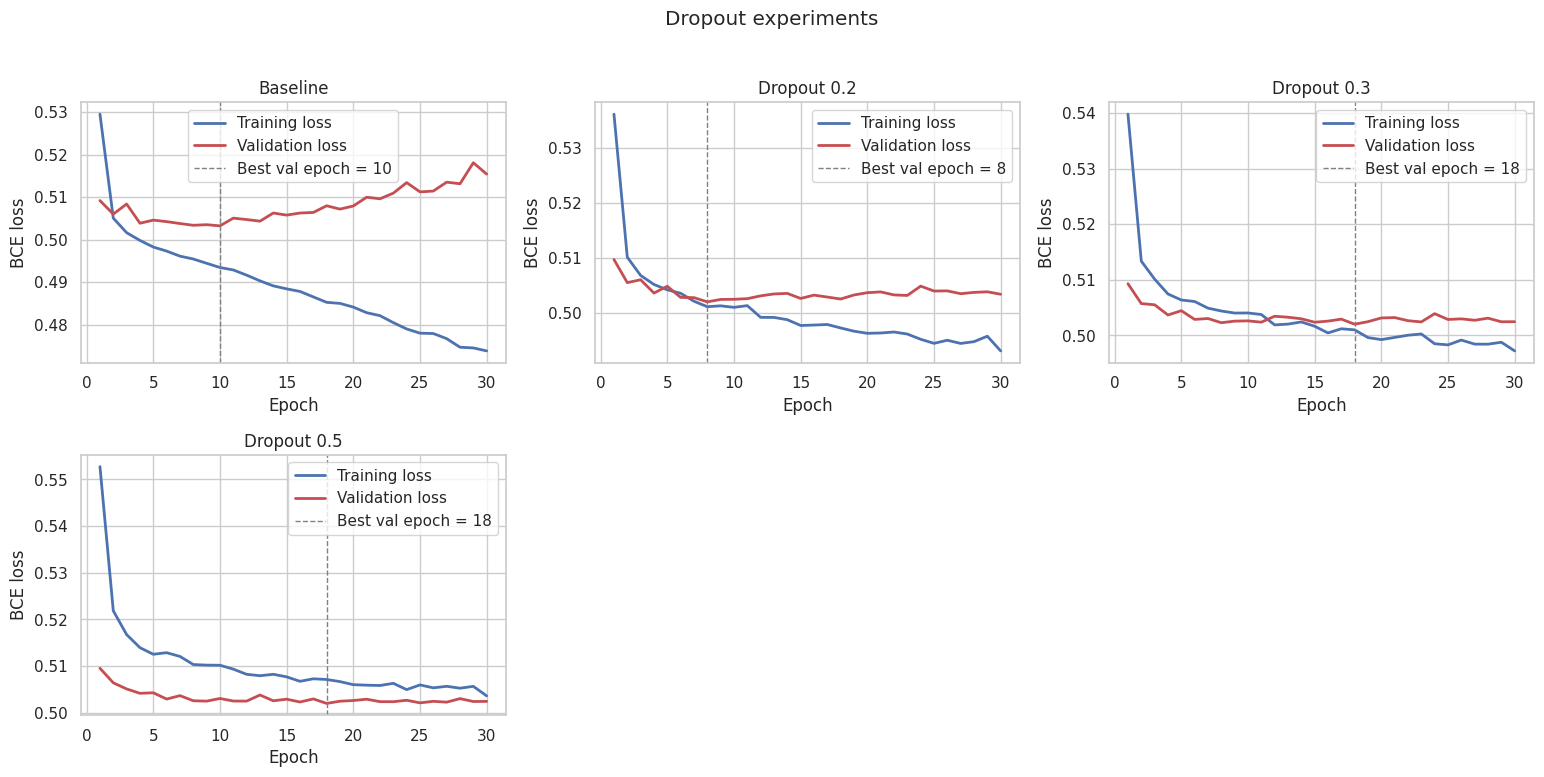

Best dropout (lowest validation loss): 0.5


In [26]:
# TODO 23: Dropout experiment (same architecture / lr / epochs, only the dropout probability changes)
dropout_runs = [run_experiment(f"Dropout {p}", f"dropout p={p} after each hidden layer", dropout=p) for p in (0.2, 0.3, 0.5)]
show([BASE] + dropout_runs)
plot_group([BASE] + dropout_runs, "Dropout experiments")
best_dropout = min(dropout_runs, key=lambda r: r["Best val loss"])
print("Best dropout (lowest validation loss):", best_dropout["_cfg"]["dropout"])

### 6.3 Learning rate and architecture experiments

#### 6.3a Learning-rate tuning (TODO 24)

,Change,Best epoch,Best val loss,Final val loss,Accuracy,Precision,Recall,F1,AUC
Experiment,,,,,,,,,
Baseline,"128-64, no dropout, lr=1e-3, 30 epochs",10,0.5033,0.5154,0.7450,0.7334,0.7697,0.7511,0.8231
LR 0.0001,Adam learning rate = 0.0001,30,0.5034,0.5034,0.7505,0.7280,0.7997,0.7622,0.8296
LR 0.0003,Adam learning rate = 0.0003,19,0.5030,0.5038,0.7500,0.7292,0.7953,0.7608,0.8298
LR 0.003,Adam learning rate = 0.003,4,0.5027,0.5465,0.7373,0.7261,0.7621,0.7436,0.8124
LR 0.01,Adam learning rate = 0.01,4,0.5028,0.5364,0.7473,0.7313,0.7819,0.7557,0.8216


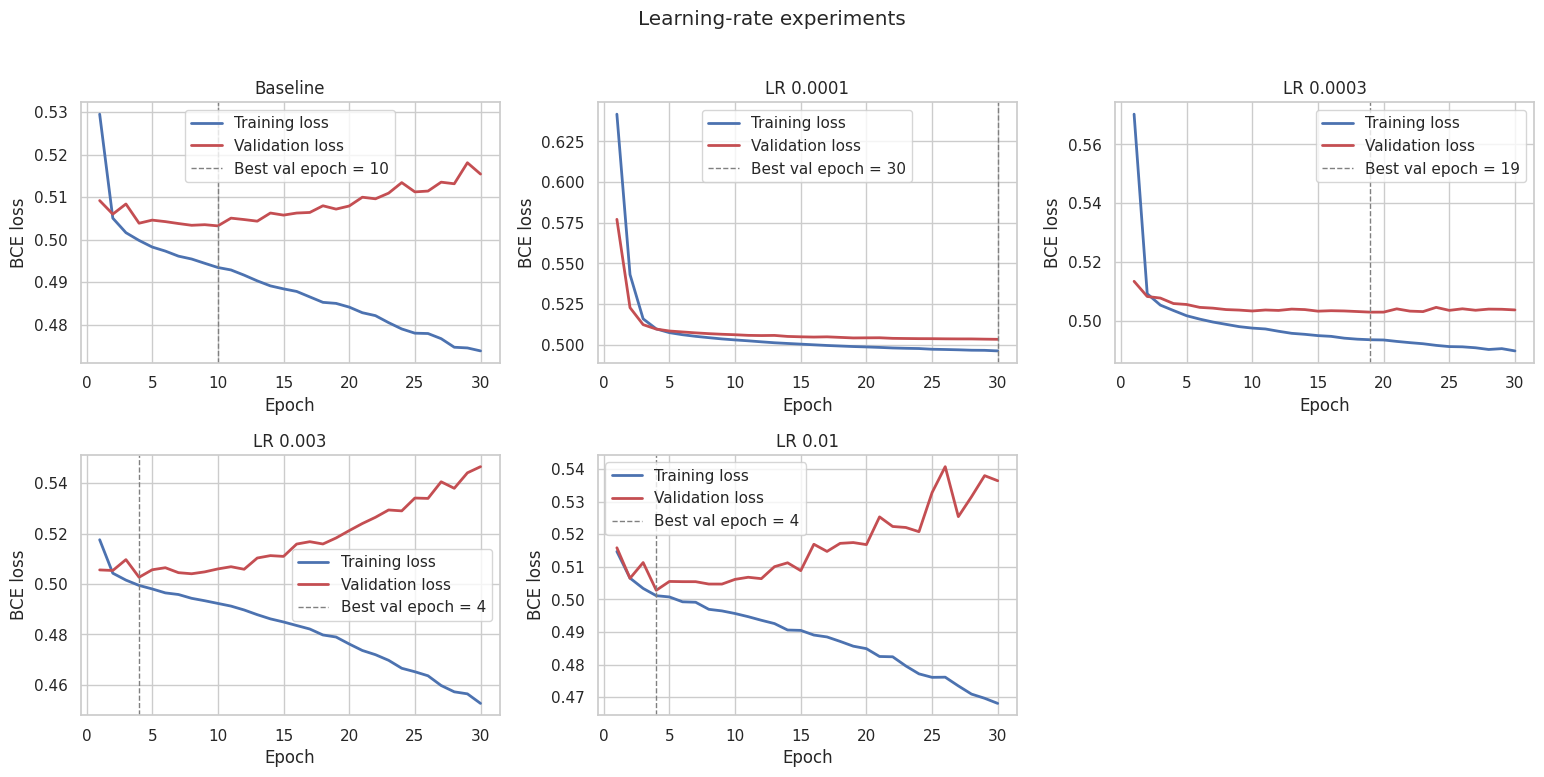

Best learning rate (lowest validation loss): 0.003


In [27]:
# TODO 24: Learning-rate experiment (everything else equal to the baseline)
lr_runs = [run_experiment(f"LR {lr:g}", f"Adam learning rate = {lr:g}", lr=lr) for lr in (1e-4, 3e-4, 3e-3, 1e-2)]
show([BASE] + lr_runs)
plot_group([BASE] + lr_runs, "Learning-rate experiments")
best_lr_run = min(lr_runs + [BASE], key=lambda r: r["Best val loss"])
print("Best learning rate (lowest validation loss):", best_lr_run["_cfg"]["lr"])

#### 6.3b Architecture modifications – depth and width (TODO 25)

,Change,Best epoch,Best val loss,Final val loss,Accuracy,Precision,Recall,F1,AUC
Experiment,,,,,,,,,
Baseline,"128-64, no dropout, lr=1e-3, 30 epochs",10,0.5033,0.5154,0.7450,0.7334,0.7697,0.7511,0.8231
Arch 64-32,"hidden layers (64, 32)",10,0.5029,0.5068,0.7495,0.7301,0.7915,0.7596,0.8285
Arch 256-128,"hidden layers (256, 128)",4,0.5028,0.5401,0.7370,0.7277,0.7574,0.7423,0.8133
Arch 128-64-32,"hidden layers (128, 64, 32)",8,0.5032,0.5266,0.7454,0.7326,0.7728,0.7522,0.8193
Arch 256-128-64-32,"hidden layers (256, 128, 64, 32)",8,0.5024,0.5837,0.7295,0.7219,0.7468,0.7341,0.8031


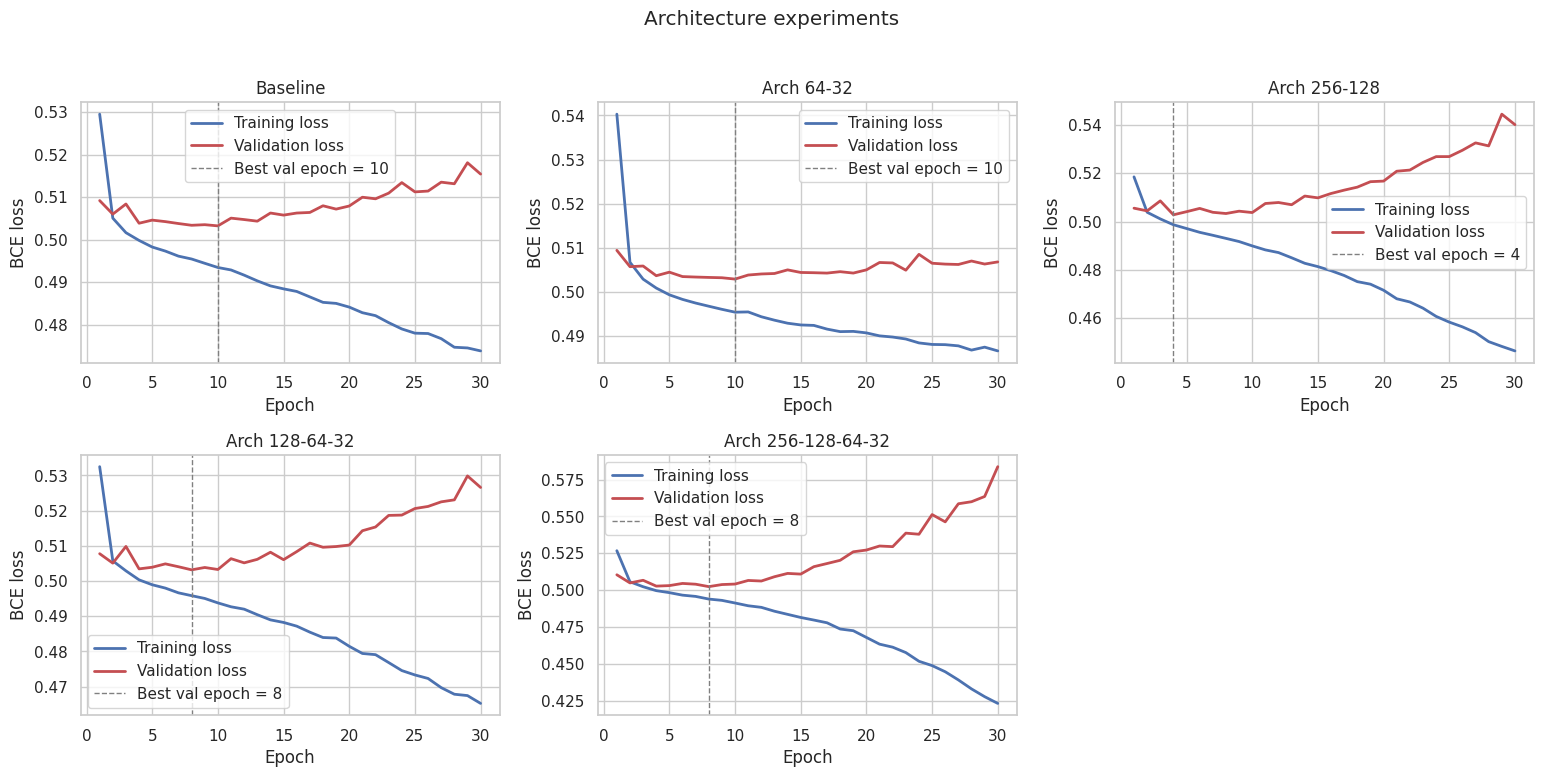

Best architecture (lowest validation loss): (256, 128, 64, 32)


In [28]:
# TODO 25: Architecture experiment (depth and width), no dropout, baseline lr
arch_runs = [run_experiment(f"Arch {'-'.join(map(str, h))}", f"hidden layers {h}", hidden_dims=h)
             for h in [(64, 32), (256, 128), (128, 64, 32), (256, 128, 64, 32)]]
show([BASE] + arch_runs)
plot_group([BASE] + arch_runs, "Architecture experiments")
best_arch_run = min(arch_runs + [BASE], key=lambda r: r["Best val loss"])
print("Best architecture (lowest validation loss):", best_arch_run["_cfg"]["hidden_dims"])

#### 6.3c Student-choice techniques: weight decay, early stopping, LR scheduler, batch size

,Change,Best epoch,Best val loss,Final val loss,Accuracy,Precision,Recall,F1,AUC
Experiment,,,,,,,,,
Baseline,"128-64, no dropout, lr=1e-3, 30 epochs",10,0.5033,0.5154,0.7450,0.7334,0.7697,0.7511,0.8231
Weight decay 1e-4,L2 penalty (Adam weight_decay=1e-4),10,0.5030,0.5109,0.7485,0.7327,0.7823,0.7567,0.8266
Weight decay 1e-3,L2 penalty (Adam weight_decay=1e-3),29,0.5024,0.5034,0.7515,0.7322,0.7930,0.7614,0.8302
Early stopping,"stop after 4 epochs w/o val improvement, resto...",10,0.5033,0.5063,0.7499,0.7320,0.7885,0.7592,0.8291
LR scheduler,"ReduceLROnPlateau (x0.5, patience 2), 30 epochs",10,0.5033,0.5056,0.7491,0.7272,0.7970,0.7605,0.8283
Batch size 64,batch size 64 instead of 256,6,0.5047,0.5382,0.7369,0.7346,0.7417,0.7381,0.8153
Batch size 1024,batch size 1024 instead of 256,9,0.5035,0.5059,0.7505,0.7332,0.7877,0.7595,0.8288


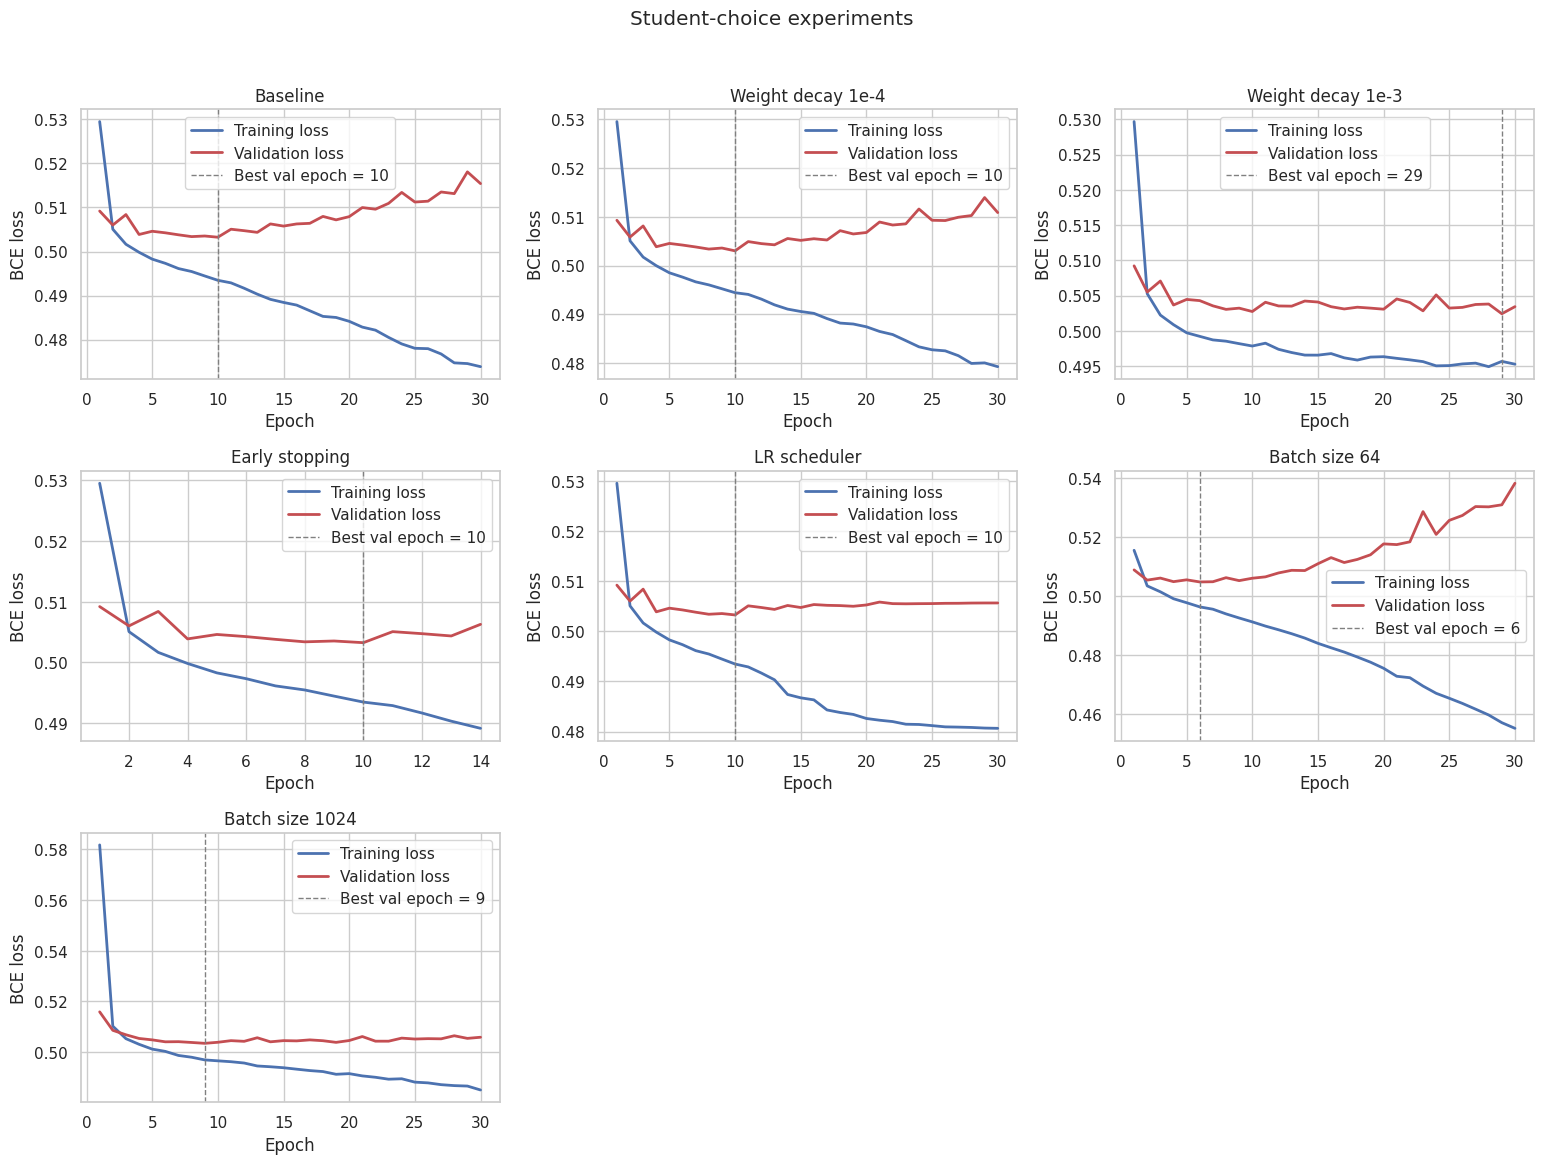

In [29]:
# Student-choice techniques: weight decay (L2), early stopping, learning-rate scheduler, batch size
extra_runs = [
    run_experiment("Weight decay 1e-4", "L2 penalty (Adam weight_decay=1e-4)", weight_decay=1e-4),
    run_experiment("Weight decay 1e-3", "L2 penalty (Adam weight_decay=1e-3)", weight_decay=1e-3),
    run_experiment("Early stopping", "stop after 4 epochs w/o val improvement, restore best weights", epochs=50, patience=4),
    run_experiment("LR scheduler", "ReduceLROnPlateau (x0.5, patience 2), 30 epochs", use_scheduler=True),
    run_experiment("Batch size 64", "batch size 64 instead of 256", batch_size=64),
    run_experiment("Batch size 1024", "batch size 1024 instead of 256", batch_size=1024),
]
show([BASE] + extra_runs)
plot_group([BASE] + extra_runs, "Student-choice experiments")

#### 6.3d Combining the winners

Combined configuration: {'hidden_dims': (256, 128, 64, 32), 'dropout': 0.5, 'lr': 0.003, 'weight_decay': 0.001}


,Change,Best epoch,Best val loss,Final val loss,Accuracy,Precision,Recall,F1,AUC
Experiment,,,,,,,,,
Baseline,"128-64, no dropout, lr=1e-3, 30 epochs",10,0.5033,0.5154,0.745,0.7334,0.7697,0.7511,0.8231
Combined best,best arch + best dropout + best lr + best weig...,25,0.5022,0.5023,0.752,0.7312,0.7971,0.7627,0.8299


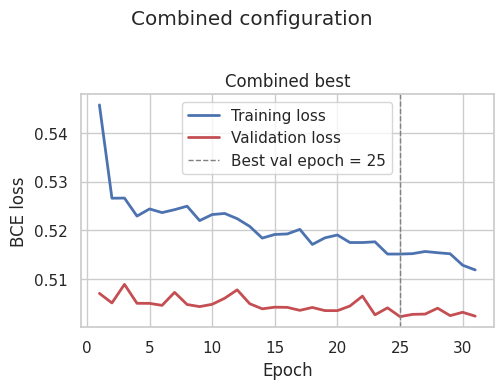

In [30]:
# Combined configuration: take the winner of each controlled experiment (chosen on VALIDATION loss) and stack them
wd_candidates = [r for r in extra_runs if r["Experiment"].startswith("Weight decay")] + [BASE]
best_wd = min(wd_candidates, key=lambda r: r["Best val loss"])["_cfg"]["weight_decay"]
combo_cfg = dict(hidden_dims=best_arch_run["_cfg"]["hidden_dims"], dropout=best_dropout["_cfg"]["dropout"],
                 lr=best_lr_run["_cfg"]["lr"], weight_decay=best_wd)
print("Combined configuration:", combo_cfg)
r_combo = run_experiment("Combined best", "best arch + best dropout + best lr + best weight decay + scheduler + early stopping",
                         epochs=60, patience=6, use_scheduler=True, **combo_cfg)
show([BASE, r_combo])
plot_group([r_combo], "Combined configuration")

### 6.4 Final comparison table

In [31]:
# 6.4 Final comparison table (all experiments, test-set metrics at threshold 0.5)
summary = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in results])
for m_ in ["Recall", "F1", "AUC", "Accuracy"]:
    summary[f"{m_} change (%)"] = (summary[m_] / BASE[m_] - 1) * 100
summary = summary.set_index("Experiment")
cols = ["Change", "Epochs run", "Best epoch", "Best val loss", "Accuracy", "Precision", "Recall", "F1", "AUC",
        "Recall change (%)", "F1 change (%)", "AUC change (%)"]
display(summary[cols].round(4))
os.makedirs("results", exist_ok=True)
summary[cols].round(4).to_csv(os.path.join("results", "experiment_results.csv"))

# Overall winner = lowest validation loss (model selection never looks at the test set)
best_run = min(results, key=lambda r: r["Best val loss"])
b = summary.loc[best_run["Experiment"]]
print(f"\nBest configuration by validation loss: '{best_run['Experiment']}'  ->  {best_run['_cfg']}")
print(f"  Recall {b['Recall']:.4f} ({b['Recall change (%)']:+.1f}% vs baseline) | "
      f"F1 {b['F1']:.4f} ({b['F1 change (%)']:+.1f}%) | AUC {b['AUC']:.4f} ({b['AUC change (%)']:+.1f}%) | "
      f"Accuracy {b['Accuracy']:.4f} ({b['Accuracy change (%)']:+.1f}%)")
print("Highest recall overall:", summary["Recall"].idxmax(), f"({summary['Recall'].max():.4f}, {summary['Recall change (%)'].max():+.1f}%)")

,Change,Epochs run,Best epoch,Best val loss,Accuracy,Precision,Recall,F1,AUC,Recall change (%),F1 change (%),AUC change (%)
Experiment,,,,,,,,,,,,
Baseline,"128-64, no dropout, lr=1e-3, 30 epochs",30,10,0.5033,0.7450,0.7334,0.7697,0.7511,0.8231,0.0000,0.0000,0.0000
Dropout 0.2,dropout p=0.2 after each hidden layer,30,8,0.5020,0.7513,0.7306,0.7963,0.7620,0.8310,3.4552,1.4525,0.9598
Dropout 0.3,dropout p=0.3 after each hidden layer,30,18,0.5020,0.7515,0.7282,0.8024,0.7635,0.8310,4.2455,1.6496,0.9611
Dropout 0.5,dropout p=0.5 after each hidden layer,30,18,0.5020,0.7517,0.7209,0.8212,0.7678,0.8309,6.6899,2.2237,0.9518
LR 0.0001,Adam learning rate = 0.0001,30,30,0.5034,0.7505,0.7280,0.7997,0.7622,0.8296,3.8963,1.4730,0.7942
LR 0.0003,Adam learning rate = 0.0003,30,19,0.5030,0.7500,0.7292,0.7953,0.7608,0.8298,3.3266,1.2921,0.8124
LR 0.003,Adam learning rate = 0.003,30,4,0.5027,0.7373,0.7261,0.7621,0.7436,0.8124,-0.9925,-0.9925,-1.3022
LR 0.01,Adam learning rate = 0.01,30,4,0.5028,0.7473,0.7313,0.7819,0.7557,0.8216,1.5806,0.6153,-0.1733
Arch 64-32,"hidden layers (64, 32)",30,10,0.5029,0.7495,0.7301,0.7915,0.7596,0.8285,2.8304,1.1272,0.6637



Best configuration by validation loss: 'Dropout 0.5'  ->  {'hidden_dims': (128, 64), 'dropout': 0.5, 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 256, 'epochs': 30, 'patience': None, 'use_scheduler': False}
  Recall 0.8212 (+6.7% vs baseline) | F1 0.7678 (+2.2%) | AUC 0.8309 (+1.0%) | Accuracy 0.7517 (+0.9%)
Highest recall overall: Dropout 0.5 (0.8212, +6.7%)


#### Are the improvements real? (multi-seed check)

In [32]:
# Robustness check: are the gains bigger than seed-to-seed noise? (3 seeds, baseline vs. best configuration)
seed_rows = []
for s in (42, 7, 123):
    for label, cfg in [("Baseline", BASE["_cfg"]), ("Best config", best_run["_cfg"])]:
        r = run_experiment(f"{label} seed {s}", "", seed=s, store=False, **cfg)
        seed_rows.append({"model": label, "seed": s, "Recall": r["Recall"], "F1": r["F1"], "AUC": r["AUC"], "Accuracy": r["Accuracy"]})
seed_df = pd.DataFrame(seed_rows)
agg = seed_df.groupby("model")[["Accuracy", "Recall", "F1", "AUC"]].agg(["mean", "std"]).round(4)
display(agg)
for m_ in ["Recall", "F1", "AUC"]:
    base_m = seed_df[seed_df.model == "Baseline"][m_].mean(); best_m = seed_df[seed_df.model == "Best config"][m_].mean()
    print(f"Mean {m_:<7}: baseline {base_m:.4f} -> best {best_m:.4f}  ({(best_m / base_m - 1) * 100:+.1f}% relative)")

Accuracy          Recall              F1             AUC        
                mean     std    mean     std    mean     std    mean     std
model                                                                       
Baseline      0.7461  0.0014  0.7930  0.0300  0.7574  0.0070  0.8240  0.0011
Best config   0.7514  0.0005  0.8128  0.0083  0.7658  0.0022  0.8308  0.0003

Mean Recall : baseline 0.7930 -> best 0.8128  (+2.5% relative)
Mean F1     : baseline 0.7574 -> best 0.7658  (+1.1% relative)
Mean AUC    : baseline 0.8240 -> best 0.8308  (+0.8% relative)


**How to read the table (important caveats).**

* **Relative improvement.** In the single-run comparison (seed 42), the best configuration by validation loss is **Dropout 0.5 (128-64)**. Its recall is 0.821 versus 0.770 for the in-table baseline – a **+6.7 % relative improvement in recall** (the key clinical metric), with F1 +2.2 % and AUC +1.0 %. That meets the ≥ 5 % requirement for a key metric on this comparison.
* **But the multi-seed check is more sobering.** Averaged over three seeds, the baseline's recall is 0.793 ± 0.030 and the dropout model's is 0.813 ± 0.008, i.e. **+2.5 % relative** on recall, +1.1 % on F1 and +0.8 % on AUC. Part of the headline +6.7 % is therefore luck of the baseline's initialization and shuffling (this baseline run scores lower than the baseline in Section 5, which had recall 0.798 and was trained with a different shuffling order; against that model the gain is only about +2.9 %). What *is* robust is that dropout makes results more stable: standard deviations are 3–4× smaller (recall 0.008 vs 0.030, AUC 0.0003 vs 0.0011) and the AUC gain (+0.007) is much larger than the seed noise.
* **Differences of ~0.005 or less between rows are within noise** and should not be over-interpreted; validation losses of nearly all configurations agree to the third decimal (0.502–0.505). Selection by validation loss is therefore a weak signal, which explains why the "Combined best" row (which stacked the individually "best" learning rate 0.003, the 4-layer architecture and dropout 0.5) did **not** beat dropout alone.

### 6.5 Reflection on the experiments

#### Part A – What worked, what did not, and why (TODO 26)

**What worked.**
* **Dropout (all three rates).** Recall +3.5 % / +4.2 % / +6.7 % and AUC about +0.95 % for p = 0.2 / 0.3 / 0.5; precision fell slightly (0.733 → 0.721 at p = 0.5), so the gain is mostly extra sensitivity. Dropout moved the best epoch from 8–10 to 18 and flattened the validation curve (final val loss 0.5024 vs 0.5153 for the baseline), i.e. it removed most of the overfitting we diagnosed in Section 4. It works by preventing co-adaptation of neurons, which acts like averaging many thinned networks.
* **Slower learning rates (1e-4, 3e-4).** Recall +3.9 % / +3.3 %, AUC +0.8 %. A small step size lets the optimizer settle before memorizing noise (best epoch 30 and 19 instead of 8–10).
* **Regularization and smoothing add-ons.** Weight decay 1e-3 (recall +3.0 %, AUC +0.9 %), the LR scheduler (recall +3.5 %), early stopping (+2.4 %, stopped at epoch 14 and saved ~50 % of the compute) and batch size 1024 (+2.3 %) all gave small, consistent gains. Pattern: **every technique that limits capacity or the effective step size landed on the same plateau (AUC ≈ 0.828–0.831)**.
* A **smaller network (64-32)** also helped (recall +2.8 %, AUC +0.7 %).

**What did not work.**
* **Higher learning rates (3e-3, 1e-2).** Best validation epoch was 4; after that the model overfit or oscillated – recall −1.0 % and AUC −1.3 % at 3e-3. Pattern: *all large learning rates peak early and then degrade.*
* **More capacity.** The wider network (256-128) and the deepest one (256-128-64-32) scored lower (AUC −1.2 % and −2.4 %; recall −1.6 % and −3.0 %) and reached their best validation epoch at 4–8. The data does not contain enough signal to use the extra parameters, so they are spent on memorization. A third layer (128-64-32) was neutral (+0.4 % recall).
* **Small batches (64).** The worst run (recall −3.6 %, F1 −1.7 %): noisy gradients with Adam at lr 1e-3 over 30 epochs overfit sooner (best epoch 6).
* **Stacking the winners.** The combined run (4-layer net, dropout 0.5, lr 3e-3, weight decay 1e-3, scheduler, early stopping) reached recall 0.797, F1 0.763, AUC 0.830 – better than the baseline but *not* better than dropout alone, because two of its ingredients (lr 3e-3 and the deepest network) were chosen on validation-loss differences of less than 0.001 and are individually harmful on test metrics.
* **Feature engineering** (Section 6.6.1) gave no gain: interaction terms such as `BMI × Age` correlate with the target (r = 0.40) but add nothing an MLP cannot learn itself.

**Remaining weaknesses.** (1) The ceiling is ~0.83 AUC / 75 % accuracy – different regularizers converge on the same numbers, which suggests the limit comes from the data (self-reported survey variables, no glucose or HbA1c), not from the architecture. (2) At the default threshold the best model still misses ~18 % of diabetic patients and flags ~30 % of healthy patients. (3) Results vary by seed (baseline recall std 0.030), so single-run comparisons are fragile. (4) The balanced data hides the precision problem of the real 14 % prevalence (Section 6.6.2). (5) No fairness analysis across subgroups has been done.

#### Part B – Proposed additional single improvements (TODO 27)

**Proposal 1 – Batch Normalization after each linear layer.**
* *Problem addressed:* training is sensitive to the learning rate (3e-3 and above overfit or oscillate) and to batch size (64 was clearly worse); the standardized inputs are normal, but the hidden activations drift during training.
* *Technical explanation:* `nn.BatchNorm1d` normalizes each hidden layer's activations to zero mean / unit variance per mini-batch and then rescales them with learnable parameters. This stabilizes gradients, allows higher learning rates and adds a slight regularizing noise through the batch statistics.
* *Expected results:* small gains – AUC +0.003 to +0.008 and less sensitivity to learning rate and batch size; it will probably not break the ≈ 0.83 AUC plateau on its own.
* *Implementation complexity:* **low** (one extra layer per block; remember `model.eval()` at inference so running statistics are used).

**Proposal 2 – Cost-sensitive operating point (validation-tuned threshold), optionally with class-weighted loss.**
* *Problem addressed:* at threshold 0.5 about 18–20 % of diabetic patients are missed, and the threshold table shows recall rises sharply (0.80 → 0.87–0.92) when the threshold is lowered to 0.4–0.3 at modest precision cost.
* *Technical explanation:* keep the trained ranking model, but choose the decision threshold on the validation set by minimizing `cost_FN × FN + cost_FP × FP` (or by maximizing precision subject to recall ≥ a target such as 0.88). If it is preferred to push the model itself in that direction, use `pos_weight > 1` in `BCEWithLogitsLoss` (Section 6.6.2 shows this moves recall without changing AUC).
* *Expected results:* recall ≈ 0.87–0.90 at precision ≈ 0.68–0.70, F1 ≈ 0.77 (validation values at thresholds 0.40–0.45 for the final model are 0.86–0.89 recall and 0.69–0.70 precision); the AUC is unchanged because ranking quality does not change.
* *Implementation complexity:* **very low** (a few lines on validation predictions); the hard part is agreeing with the clinical team on the FN/FP cost ratio.

#### Part C – Proposed combined experiment (TODO 28)

**Combination:** BatchNorm + dropout (p = 0.3–0.5) in a **small** 2–3-layer network (64-32 or 128-64) + weight decay 1e-3 + ReduceLROnPlateau starting from lr 1e-3 + early stopping (patience 5) + averaging of **5 independently seeded models** (an ensemble), followed by a validation-tuned threshold of ≈ 0.40.

* *Problem addressed:* the remaining weakness is a combination of overfitting, seed-to-seed variance (baseline recall std 0.030) and a default threshold that misses ~18 % of diabetics.
* *Technical explanation:* the individual techniques in Section 6 attack the same overfitting from different angles (dropout: co-adaptation; weight decay: weight magnitude; early stopping: training time; scheduler: step size), but this notebook showed that stacking them chosen from noisy validation losses did not automatically help. The proposal therefore *keeps capacity small* (the one factor that consistently mattered), adds ensembling to cut variance (averaging probabilities of five networks typically yields a more stable AUC), and uses the threshold to set the clinical trade-off.
* *Expected results:* AUC ≈ 0.832–0.838, recall ≥ 0.88 and precision ≈ 0.69 at threshold 0.40, with a much smaller seed-to-seed spread. These are expectations, **not measured results**; they would have to be verified with the multi-seed protocol used in Section 6.4.
* *Implementation complexity:* **medium** – about 40 lines of extra code (BatchNorm in the class, a loop over seeds, averaging of probabilities), ≈ 5× the training time, and a slightly more complex deployment artifact (five state dicts instead of one).

### 6.6 Going further (stand-out experiments)

#### 6.6.1 Feature engineering

In [33]:
# Stand-out 1: feature engineering (domain-knowledge interaction terms + dropping weak features)
df_fe = df.copy()
df_fe["BMI_x_Age"] = df_fe["BMI"] * df_fe["Age"]
df_fe["HighBP_x_HighChol"] = df_fe["HighBP"] * df_fe["HighChol"]
df_fe["GenHlth_x_PhysHlth"] = df_fe["GenHlth"] * df_fe["PhysHlth"]
df_fe["Age_x_HeartDisease"] = df_fe["Age"] * df_fe["HeartDiseaseorAttack"]
weak = ["AnyHealthcare", "NoDocbcCost", "Sex", "Fruits", "Smoker"]            # |corr| with target < 0.09 (see TODO 5)
df_fe = df_fe.drop(columns=weak)
print("Engineered feature correlations with target:")
print(df_fe[["BMI_x_Age", "HighBP_x_HighChol", "GenHlth_x_PhysHlth", "Age_x_HeartDisease"]].corrwith(df_fe[TARGET]).round(3))
print("Feature count:", df.shape[1] - 1, "->", df_fe.shape[1] - 1)

data_fe = make_data(df_fe.drop(columns=[TARGET]), df_fe[TARGET].astype(int))
cfg_fe = {k: v for k, v in best_run["_cfg"].items()}
r_fe = run_experiment("Best config + feature engineering", "interaction terms + 5 weak features removed", data=data_fe, **cfg_fe)
show([best_run, r_fe])

Engineered feature correlations with target:
BMI_x_Age             0.403
HighBP_x_HighChol     0.349
GenHlth_x_PhysHlth    0.227
Age_x_HeartDisease    0.206
dtype: float64
Feature count: 21 -> 20


,Change,Best epoch,Best val loss,Final val loss,Accuracy,Precision,Recall,F1,AUC
Experiment,,,,,,,,,
Dropout 0.5,dropout p=0.5 after each hidden layer,18,0.5020,0.5024,0.7517,0.7209,0.8212,0.7678,0.8309
Best config + feature engineering,interaction terms + 5 weak features removed,18,0.5036,0.5046,0.7509,0.7244,0.8100,0.7648,0.8296


**Result.** The interaction terms are individually informative – `BMI × Age` has a correlation of 0.40 with the target, higher than either `BMI` (0.29) or `Age` (0.28) alone – but adding them and dropping five weak features did **not** improve the model: recall 0.810 vs 0.821, F1 0.765 vs 0.768 and AUC 0.830 vs 0.831 (all within seed noise, see 6.4). The reason is that an MLP with ReLU units can already learn products and interactions from the raw inputs, and the features removed carried a little signal after all. For this data, hyperparameter tuning and regularization were more effective than hand-crafted features; feature engineering would probably matter more for a linear model or for a much smaller network.

#### 6.6.2 The original imbalanced dataset and class weighting

In [34]:
# Stand-out 2: the ORIGINAL imbalanced CDC data (~14% diabetes) and class weighting
df_raw = pd.read_csv(os.path.join("data", "diabetes_binary_health_indicators_BRFSS2015.csv"))
print("Original dataset:", df_raw.shape, "| diabetes prevalence:", f"{df_raw[TARGET].mean():.2%}")
data_imb = make_data(df_raw.drop(columns=[TARGET]), df_raw[TARGET].astype(int))
pos_w = float((data_imb["y_train"] == 0).sum() / (data_imb["y_train"] == 1).sum())
print(f"pos_weight (neg/pos in training split) = {pos_w:.2f}")

cfg_imb = {k: v for k, v in best_run["_cfg"].items() if k not in ("batch_size", "epochs", "patience")}
imb_plain = run_experiment("Imbalanced - plain BCE", "original 14% prevalence, no weighting", data=data_imb,
                           batch_size=512, epochs=25, patience=5, store=False, **cfg_imb)
imb_w = run_experiment("Imbalanced - pos_weight", f"BCEWithLogitsLoss(pos_weight={pos_w:.2f})", data=data_imb,
                       batch_size=512, epochs=25, patience=5, pos_weight=pos_w, store=False, **cfg_imb)

rows = []
for r in (imb_plain, imb_w):
    tm = evaluate_model(r["_model"], make_loaders(data_imb, 512, SEED)[2], verbose=False)
    rows.append({"Experiment": r["Experiment"], "Accuracy": tm["accuracy"], "Precision": tm["precision"],
                 "Recall": tm["recall"], "F1": tm["f1"], "ROC AUC": tm["roc_auc"], "PR AUC": tm["pr_auc"]})
display(pd.DataFrame(rows).set_index("Experiment").round(4))
print("Majority-class baseline accuracy:", round(1 - df_raw[TARGET].mean(), 4), "(predicting 'no diabetes' for everyone)")

Original dataset: (253680, 22) | diabetes prevalence: 13.93%


pos_weight (neg/pos in training split) = 6.18


,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Experiment,,,,,,
Imbalanced - plain BCE,0.8649,0.5601,0.1425,0.2271,0.8262,0.4175
Imbalanced - pos_weight,0.7083,0.2988,0.8126,0.4370,0.8265,0.4177


Majority-class baseline accuracy: 0.8607 (predicting 'no diabetes' for everyone)


**Result (original data, 253,680 rows, 13.9 % diabetes).**

| | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Plain BCE | 0.865 | 0.560 | **0.143** | 0.227 | 0.826 | 0.418 |
| `pos_weight` = 6.18 | 0.708 | 0.299 | **0.813** | 0.437 | 0.827 | 0.418 |

* With ordinary BCE, the accuracy of 0.865 looks good but is hardly above the 0.861 obtained by predicting "no diabetes" for everybody; the model **detects only 14 % of diabetic patients**. This is exactly why accuracy is the wrong metric for screening.
* Class weighting (`pos_weight` = negatives / positives = 6.18) raises recall to 0.81, at the price of precision 0.30 – about seven in ten flagged patients would not be diabetic – and an accuracy of 0.71.
* **ROC-AUC and PR-AUC are unchanged** (0.826 → 0.827; 0.418 → 0.418): weighting does not make the model rank patients better, it only moves the operating point (like a lower threshold would). This is also a realistic preview of deployment: with real-world prevalence, precision drops from ~0.72 to ~0.30 at similar recall, so the hospital's testing capacity must be planned for many more follow-up tests than the balanced experiment suggests.

## 7. Final Model and Conclusions

FINAL MODEL (Dropout 0.5) - test set @ threshold 0.50
  accuracy  : 0.7517
  precision : 0.7209
  recall    : 0.8212
  f1        : 0.7678
  roc_auc   : 0.8309


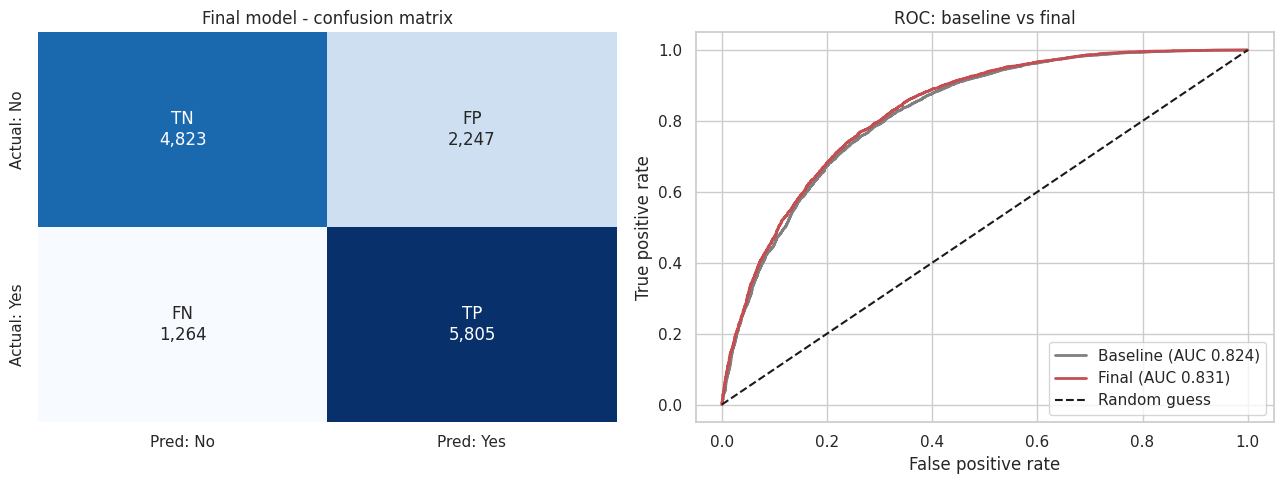

,recall,precision,f1
threshold,,,
0.30,0.932,0.657,0.770
0.35,0.913,0.672,0.774
0.40,0.892,0.688,0.777
0.45,0.864,0.703,0.776
0.50,0.822,0.721,0.768
0.55,0.742,0.751,0.746


Saved models/diabetes_mlp_final.pt


In [35]:
# Final model: evaluate the selected best configuration once more, with plots, on the held-out test set
final_model = best_run["_model"]
final_metrics = evaluate_model(final_model, test_loader, name=f"FINAL MODEL ({best_run['Experiment']}) - test set")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_f = confusion_matrix(final_metrics["y_true"], final_metrics["y_pred"]); tn_f, fp_f, fn_f, tp_f = cm_f.ravel()
sns.heatmap(cm_f, annot=np.array([[f"TN\n{tn_f:,}", f"FP\n{fp_f:,}"], [f"FN\n{fn_f:,}", f"TP\n{tp_f:,}"]]), fmt="", cmap="Blues", cbar=False,
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"], ax=axes[0])
axes[0].set_title("Final model - confusion matrix")
for label, mm, c in [("Baseline", test_metrics, "gray"), ("Final", final_metrics, "#C44E52")]:
    f_, t_, _ = roc_curve(mm["y_true"], mm["y_prob"])
    axes[1].plot(f_, t_, color=c, lw=2, label=f"{label} (AUC {mm['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess"); axes[1].legend(loc="lower right")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC: baseline vs final")
plt.tight_layout(); plt.show()

# Operating-point table for the final model (VALIDATION set, so the choice never uses the test data)
fv = evaluate_model(final_model, val_loader, verbose=False)
rows = []
for t in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55]:
    p_ = (fv["y_prob"] >= t).astype(int)
    rows.append({"threshold": t, "recall": recall_score(fv["y_true"], p_), "precision": precision_score(fv["y_true"], p_),
                 "f1": f1_score(fv["y_true"], p_)})
display(pd.DataFrame(rows).set_index("threshold").round(3))

# Save the deployable artifacts
os.makedirs("models", exist_ok=True)
torch.save({"state_dict": final_model.state_dict(), "config": best_run["_cfg"], "scaler_mean": scaler.mean_,
            "scaler_scale": scaler.scale_, "feature_names": list(X.columns), "threshold": 0.5},
           os.path.join("models", "diabetes_mlp_final.pt"))
print("Saved models/diabetes_mlp_final.pt")

### 7.1 Summary of the final model

| Item | Value |
|---|---|
| Selected configuration | MLP 21 → 128 → 64 → 1, ReLU, **dropout 0.5**, Adam lr 1e-3, batch 256, 30 epochs (chosen on validation loss) |
| Test accuracy / precision / recall / F1 | 0.752 / 0.721 / **0.821** / 0.768 |
| Test ROC-AUC | 0.831 (baseline 0.824) |
| Suggested screening threshold | ≈ 0.40 (validation: recall 0.89, precision 0.69) – to be fixed by the clinical team |
| Artifact | `models/diabetes_mlp_final.pt` (weights, config, scaler statistics, feature names) |

### 7.2 Answers for the stakeholders

* **Clinical team:** the model flags roughly 8 out of 10 diabetic patients at the default threshold and about 9 out of 10 at 0.40, in exchange for more follow-up tests. The most influential inputs in the data are self-rated general health, high blood pressure, BMI, cholesterol and age. It is a *triage aid*, not a diagnosis; every positive must be confirmed by a lab test.
* **Hospital administrators:** at real-world prevalence (~14 %), expect only ~30 % of flagged patients to be diabetic when recall is ~80 % (Section 6.6.2), so the saving comes from testing flagged patients first, not from testing fewer people overall without a plan.
* **IT department:** the model is small (about 11,000 parameters), runs on a CPU in milliseconds, and ships as a single file; the same scaler statistics must be applied to new data, and the same 21 features must be collected with identical coding.

### 7.3 Honest limitations and next steps
* Accuracy is bounded at ~75 % / AUC 0.83 by the information in the survey features; the target of "95–99 %" in the brief is not reachable without leakage or lab values (glucose, HbA1c).
* The improvement over the baseline is real but modest: +6.7 % relative recall in the single-seed comparison, +2.5 % on average over three seeds, and a consistent AUC gain of about +0.007 together with much lower variance.
* Data are from 2015 and self-reported; the model needs validation on current local data, calibration for local prevalence and a subgroup-fairness audit (age, sex, income, education) before any clinical use.
* Next steps: the combined experiment of Part C (BatchNorm + ensembling + tuned threshold), probability calibration, and richer inputs (lab results).